In [2]:
#imports
from tldhamburg.backend import DataFetcher,Things
import time
from datetime import datetime, timedelta
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import os
import json

fetcher = DataFetcher.DataFetcher()

In [2]:
#get valid Thing ID
endpoint = "Things"
params = {
    "$top" : 1,
    "$select" : "id"
}

fetcher.fetch_data(endpoint,params)

if fetcher.get_data():
    thing_id = fetcher.get_data()[0]["@iot.id"]

In [ ]:
thing = Things.Things([thing_id])

def wait_n_hours(now,n):
    end_time = now + timedelta(hours=n)
    while datetime.now() < end_time:
        time.sleep(1)

def save_data(data: dict):
    try:
        path = "/Users/mk/OneDrive/Studium/WS24_25/Projekt/ci-s-projekt-2024-mikko/tldhamburg/backend/Notebooks"
        filename = "latency_analysis.json"
        file_path = os.path.join(path,filename)
        with open(file_path,"r") as file:
            current_data = json.load(file)
    except:
        print(f"couldn't open file: {file_path} at {datetime.now()}")

    current_data.update(data)

    try:
        with open(file_path,"w") as file:
            json.dump(current_data,file,indent=4)
    except Exception as e:
        print(f"couldn't save file: {file_path} at {datetime.now()} : {e}")


while True:
    try:
        now = datetime.now()
        response_times = list()
        for i in range(100):
            try:
                start = time.time()
                obs = thing.get_primary_signal_observations(20)
                end = time.time()
                response_times.append(end - start)
            except Exception as e:
                print(f"Fehler bei Anfrage {i}: {e}")
                response_times.append(None) 

            data = {
                str(datetime.now()) : response_times
            }

        save_data(data)   
        print(f"Done Iteration at {now}")
    except Exception as e:
        print(f"Fehler in der Hauptschleife: {e}")
    wait_n_hours(now,4)


In [1]:
print(all_response_times.keys())

NameError: name 'all_response_times' is not defined

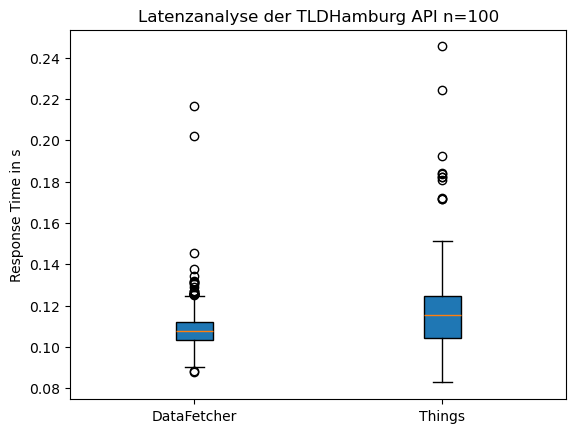

In [ ]:
# Create the boxplot
plt.boxplot(response_times, patch_artist=True)

# Add labels and title
plt.title("Multiple Boxplots")
plt.xticks([1, 2], ["DataFetcher", "Things"])  # Custom x-axis labels
plt.ylabel("Response Time in s")
plt.title("Latenzanalyse der TLDHamburg API n=100")

# Show the plot
plt.show()

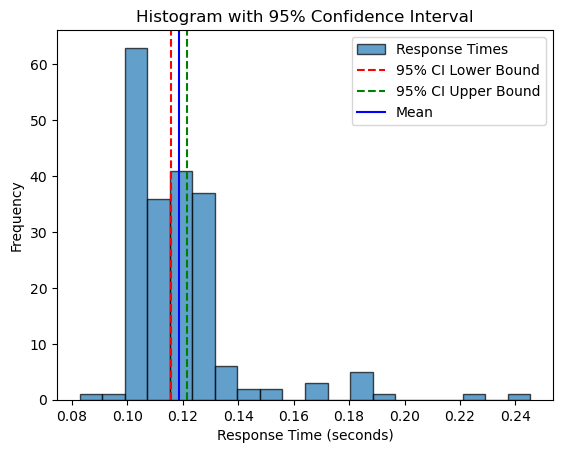

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sample response times

# Plot the histogram
plt.hist(response_times, bins=20, edgecolor='black', alpha=0.7, label="Response Times")

# Add labels and legend
plt.title("Histogram with 95% Confidence Interval")
plt.xlabel("Response Time (seconds)")
plt.ylabel("Frequency")
plt.legend()
plt.show()
